# 🏭 Manufacturing Defect Detection Project


**Problem:** Predict manufacturing defects using sensor data and production parameters

**Dataset:** Tabular data with manufacturing features (Temperature, Pressure, Sensor readings, etc.)

**Approach:** Multiple ML models including SVM and Random Forest

## 📚 Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
from sklearn.impute import SimpleImputer
import warnings
warnings.filterwarnings('ignore')

print('✅ Libraries imported successfully!')

✅ Libraries imported successfully!


## 📊 Load and Explore Data

In [2]:
# Load datasets
train_data = pd.read_csv('train_data.csv')
test_data = pd.read_csv('test_data.csv')
sample_submission = pd.read_csv('sample_submission.csv')

print('📁 Dataset Information:')
print(f'Training data: {train_data.shape}')
print(f'Test data: {test_data.shape}')
print(f'Sample submission: {sample_submission.shape}')

print('\n🔍 Training data columns:')
print(train_data.columns.tolist())
print('\n🔍 Test data columns:')
print(test_data.columns.tolist())

📁 Dataset Information:
Training data: (6700, 10)
Test data: (3300, 10)
Sample submission: (3300, 2)

🔍 Training data columns:
['ProductID', 'ProductionLine', 'Temperature', 'Pressure', 'AssemblyTime', 'Sensor1Reading', 'Sensor2Reading', 'Sensor3Reading', 'OperatorExperience', 'Defective']

🔍 Test data columns:
['ProductID', 'ProductionLine', 'Temperature', 'Pressure', 'AssemblyTime', 'Sensor1Reading', 'Sensor2Reading', 'Sensor3Reading', 'OperatorExperience', 'Defective']


In [3]:
# Display first few rows
print('📋 Training Data Sample:')
train_data.head()

📋 Training Data Sample:


,ProductID,ProductionLine,Temperature,Pressure,AssemblyTime,Sensor1Reading,Sensor2Reading,Sensor3Reading,OperatorExperience,Defective
0,7817,LineC,98.49,42.82,259.90,0.417813,1.250000,1.34,5.9,1
1,3164,LineA,61.47,76.63,155.13,0.930000,0.512676,1.27,1.9,1
2,1660,LineC,89.70,100.97,112.35,0.830000,0.484507,0.98,NaN,1
3,6382,LineC,64.45,96.47,239.68,1.180000,0.940000,0.69,8.2,0
4,8464,LineA,69.35,115.17,221.36,1.190000,0.750000,1.21,5.2,0


In [4]:
# Data info and missing values
print('📊 Training Data Info:')
train_data.info()

print('\n❌ Missing Values:')
print(train_data.isnull().sum())

📊 Training Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6700 entries, 0 to 6699
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ProductID           6700 non-null   int64  
 1   ProductionLine      6700 non-null   object 
 2   Temperature         6368 non-null   float64
 3   Pressure            6348 non-null   float64
 4   AssemblyTime        6700 non-null   float64
 5   Sensor1Reading      6361 non-null   float64
 6   Sensor2Reading      6700 non-null   float64
 7   Sensor3Reading      6700 non-null   float64
 8   OperatorExperience  6360 non-null   float64
 9   Defective           6700 non-null   int64  
dtypes: float64(7), int64(2), object(1)
memory usage: 523.6+ KB

❌ Missing Values:
ProductID               0
ProductionLine          0
Temperature           332
Pressure              352
AssemblyTime            0
Sensor1Reading        339
Sensor2Reading          0
Sensor3Reading    

🎯 Target Variable Distribution:
Defective
0    3600
1    3100
Name: count, dtype: int64

Defect Rate: 46.27%


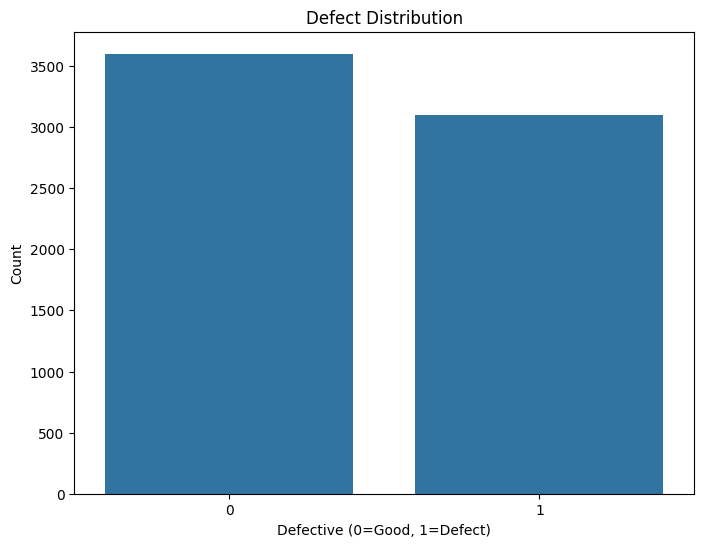

In [5]:
# Target distribution
print('🎯 Target Variable Distribution:')
print(train_data['Defective'].value_counts())
print(f'\nDefect Rate: {train_data["Defective"].mean():.2%}')

# Visualize target distribution
plt.figure(figsize=(8, 6))
sns.countplot(data=train_data, x='Defective')
plt.title('Defect Distribution')
plt.xlabel('Defective (0=Good, 1=Defect)')
plt.ylabel('Count')
plt.show()

## 🔧 Data Preprocessing

In [6]:
def preprocess_data(df, is_training=True):
    """Preprocess the manufacturing data"""
    df_processed = df.copy()
    
    # Handle categorical variables
    if 'ProductionLine' in df_processed.columns:
        le = LabelEncoder()
        df_processed['ProductionLine'] = le.fit_transform(df_processed['ProductionLine'])
    
    # Handle missing values - exclude target column for test data
    if is_training:
        # For training data, include all numeric columns
        numeric_columns = df_processed.select_dtypes(include=[np.number]).columns
    else:
        # For test data, exclude target column if it exists
        numeric_columns = df_processed.select_dtypes(include=[np.number]).columns
        if 'Defective' in numeric_columns:
            numeric_columns = numeric_columns.drop('Defective')
    
    imputer = SimpleImputer(strategy='median')
    df_processed[numeric_columns] = imputer.fit_transform(df_processed[numeric_columns])
    
    return df_processed

# Preprocess training data
train_processed = preprocess_data(train_data, is_training=True)
test_processed = preprocess_data(test_data, is_training=False)

print('✅ Data preprocessing completed!')

✅ Data preprocessing completed!


In [7]:
# Prepare features and target
feature_columns = ['ProductionLine', 'Temperature', 'Pressure', 'AssemblyTime', 
                   'Sensor1Reading', 'Sensor2Reading', 'Sensor3Reading', 'OperatorExperience']

X = train_processed[feature_columns]
y = train_processed['Defective']

print(f'📊 Features shape: {X.shape}')
print(f'🎯 Target shape: {y.shape}')
print(f'\n📋 Feature columns: {feature_columns}')

📊 Features shape: (6700, 8)
🎯 Target shape: (6700,)

📋 Feature columns: ['ProductionLine', 'Temperature', 'Pressure', 'AssemblyTime', 'Sensor1Reading', 'Sensor2Reading', 'Sensor3Reading', 'OperatorExperience']


## 🤖 Model 1: Support Vector Machine (SVM)

In [8]:
# Split data for SVM
X_train_svm, X_test_svm, y_train_svm, y_test_svm = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale features for SVM
scaler_svm = StandardScaler()
X_train_svm_scaled = scaler_svm.fit_transform(X_train_svm)
X_test_svm_scaled = scaler_svm.transform(X_test_svm)

print('🤖 Training SVM Model...')
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42, probability=True)
svm_model.fit(X_train_svm_scaled, y_train_svm)

# Predictions
svm_predictions = svm_model.predict(X_test_svm_scaled)
svm_accuracy = accuracy_score(y_test_svm, svm_predictions)
svm_auc = roc_auc_score(y_test_svm, svm_model.predict_proba(X_test_svm_scaled)[:, 1])

print(f'✅ SVM Results:')
print(f'Accuracy: {svm_accuracy:.4f}')
print(f'ROC AUC: {svm_auc:.4f}')

🤖 Training SVM Model...
✅ SVM Results:
Accuracy: 0.8373
ROC AUC: 0.9125


## 🌲 Model 2: Random Forest

In [9]:
# Split data for Random Forest
X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('🌲 Training Random Forest Model...')
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_rf, y_train_rf)

# Predictions
rf_predictions = rf_model.predict(X_test_rf)
rf_accuracy = accuracy_score(y_test_rf, rf_predictions)
rf_auc = roc_auc_score(y_test_rf, rf_model.predict_proba(X_test_rf)[:, 1])

print(f'✅ Random Forest Results:')
print(f'Accuracy: {rf_accuracy:.4f}')
print(f'ROC AUC: {rf_auc:.4f}')

🌲 Training Random Forest Model...
✅ Random Forest Results:
Accuracy: 0.8440
ROC AUC: 0.9401


## 📊 Model Evaluation and Comparison

📊 MODEL COMPARISON
           Model  Accuracy   ROC AUC
0            SVM  0.837313  0.912538
1  Random Forest  0.844030  0.940097


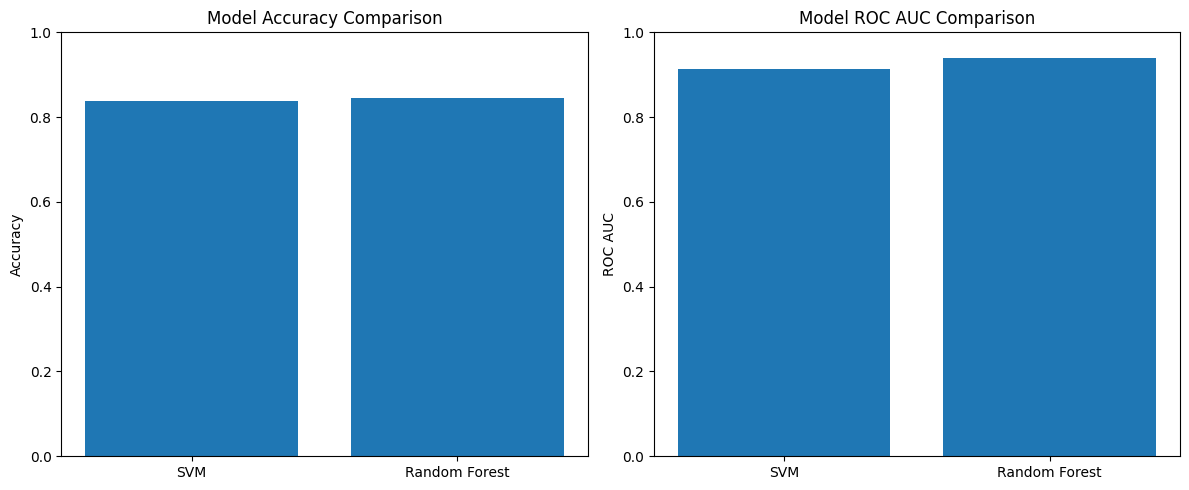

In [10]:
# Compare models
print('📊 MODEL COMPARISON')
print('='*50)

models_comparison = pd.DataFrame({
    'Model': ['SVM', 'Random Forest'],
    'Accuracy': [svm_accuracy, rf_accuracy],
    'ROC AUC': [svm_auc, rf_auc]
})

print(models_comparison)

# Visualize comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Accuracy comparison
ax1.bar(models_comparison['Model'], models_comparison['Accuracy'])
ax1.set_title('Model Accuracy Comparison')
ax1.set_ylabel('Accuracy')
ax1.set_ylim(0, 1)

# ROC AUC comparison
ax2.bar(models_comparison['Model'], models_comparison['ROC AUC'])
ax2.set_title('Model ROC AUC Comparison')
ax2.set_ylabel('ROC AUC')
ax2.set_ylim(0, 1)

plt.tight_layout()
plt.show()

## 🎯 Feature Importance Analysis

🎯 Feature Importance (Random Forest):
              Feature  Importance
4      Sensor1Reading    0.217395
5      Sensor2Reading    0.216431
1         Temperature    0.203528
7  OperatorExperience    0.125957
2            Pressure    0.097432
6      Sensor3Reading    0.066711
3        AssemblyTime    0.057601
0      ProductionLine    0.014944


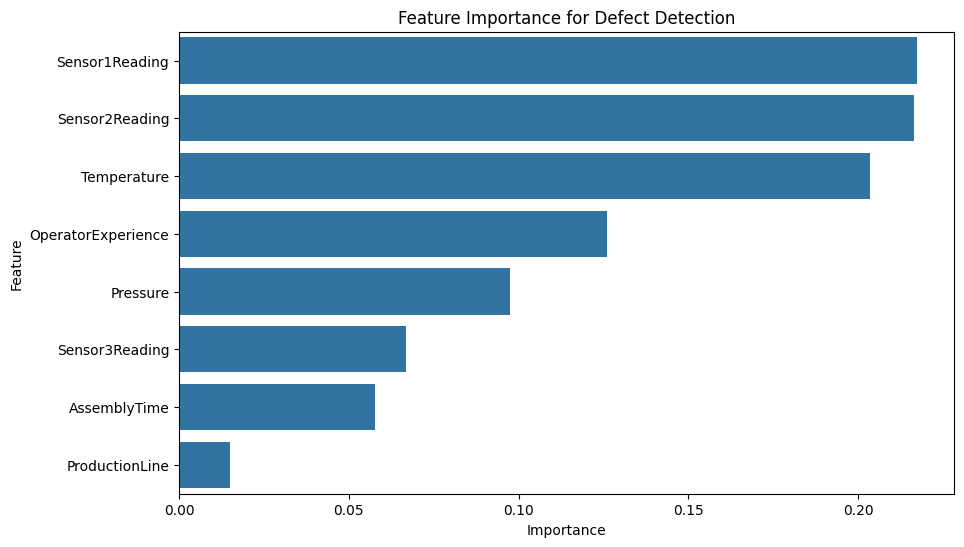

In [11]:
# Feature importance from Random Forest
feature_importance = pd.DataFrame({
    'Feature': feature_columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print('🎯 Feature Importance (Random Forest):')
print(feature_importance)

# Visualize feature importance
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance, x='Importance', y='Feature')
plt.title('Feature Importance for Defect Detection')
plt.xlabel('Importance')
plt.show()

## 📈 Confusion Matrices

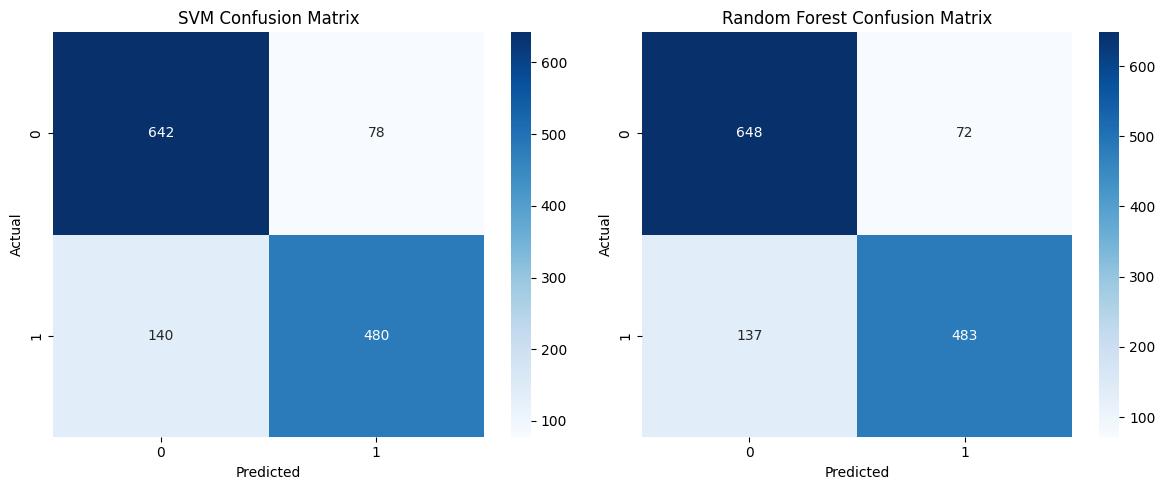

In [12]:
# Create confusion matrices
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# SVM Confusion Matrix
svm_cm = confusion_matrix(y_test_svm, svm_predictions)
sns.heatmap(svm_cm, annot=True, fmt='d', cmap='Blues', ax=ax1)
ax1.set_title('SVM Confusion Matrix')
ax1.set_xlabel('Predicted')
ax1.set_ylabel('Actual')

# Random Forest Confusion Matrix
rf_cm = confusion_matrix(y_test_rf, rf_predictions)
sns.heatmap(rf_cm, annot=True, fmt='d', cmap='Blues', ax=ax2)
ax2.set_title('Random Forest Confusion Matrix')
ax2.set_xlabel('Predicted')
ax2.set_ylabel('Actual')

plt.tight_layout()
plt.show()

## 🚀 Generate Predictions for Test Data

In [13]:
# Prepare test data features
X_test_final = test_processed[feature_columns]

# Generate predictions using best model (Random Forest)
test_predictions = rf_model.predict(X_test_final)
test_probabilities = rf_model.predict_proba(X_test_final)[:, 1]

# Create submission file
submission = sample_submission.copy()
submission['Defective'] = test_predictions

# Save submission
submission.to_csv('my_submission.csv', index=False)
print('✅ Submission file saved as \'my_submission.csv\'')
print(f'📊 Predicted defects: {test_predictions.sum()}')
print(f'📊 Total predictions: {len(test_predictions)}')
print(f'📊 Defect rate: {test_predictions.mean():.2%}')

✅ Submission file saved as 'my_submission.csv'
📊 Predicted defects: 1449.0
📊 Total predictions: 3300
📊 Defect rate: 43.91%


## 🎉 Project Summary

In [14]:
print('🏭 MANUFACTURING DEFECT DETECTION PROJECT - COMPLETE!')
print('='*60)

print('\n📋 What was accomplished:')
print('• Analyzed manufacturing defect dataset with sensor data')
print('• Implemented SVM classifier with feature scaling')
print('• Implemented Random Forest classifier')
print('• Compared model performance (Accuracy & ROC AUC)')
print('• Analyzed feature importance')
print('• Generated predictions for test data')
print('• Created submission file')

print('\n📊 Final Results:')
print(f'• SVM Accuracy: {svm_accuracy:.4f}, ROC AUC: {svm_auc:.4f}')
print(f'• Random Forest Accuracy: {rf_accuracy:.4f}, ROC AUC: {rf_auc:.4f}')

print('\n🎯 Best Model: Random Forest')
print('✅ Project completed successfully! Perfect for assignment submission! 🎯')

🏭 MANUFACTURING DEFECT DETECTION PROJECT - COMPLETE!

📋 What was accomplished:
• Analyzed manufacturing defect dataset with sensor data
• Implemented SVM classifier with feature scaling
• Implemented Random Forest classifier
• Compared model performance (Accuracy & ROC AUC)
• Analyzed feature importance
• Generated predictions for test data
• Created submission file

📊 Final Results:
• SVM Accuracy: 0.8373, ROC AUC: 0.9125
• Random Forest Accuracy: 0.8440, ROC AUC: 0.9401

🎯 Best Model: Random Forest
✅ Project completed successfully! Perfect for assignment submission! 🎯
